
========== TRAINING FOR PM2.5 ==========
Currently tuning: RandomForest...
Currently tuning: GradientBoosting...
Currently tuning: XGBoost...
Currently tuning: LightGBM...

--- PM2.5 MODEL COMPARISON ---
                     R2   RMSE    MAE
GradientBoosting  0.733  19.81  13.61
XGBoost           0.732  19.87  13.77
LightGBM          0.711  20.61  14.48
RandomForest      0.696  21.15  14.09

 PLOTTING AVERAGE FEATURE IMPORTANCE (PM2.5)


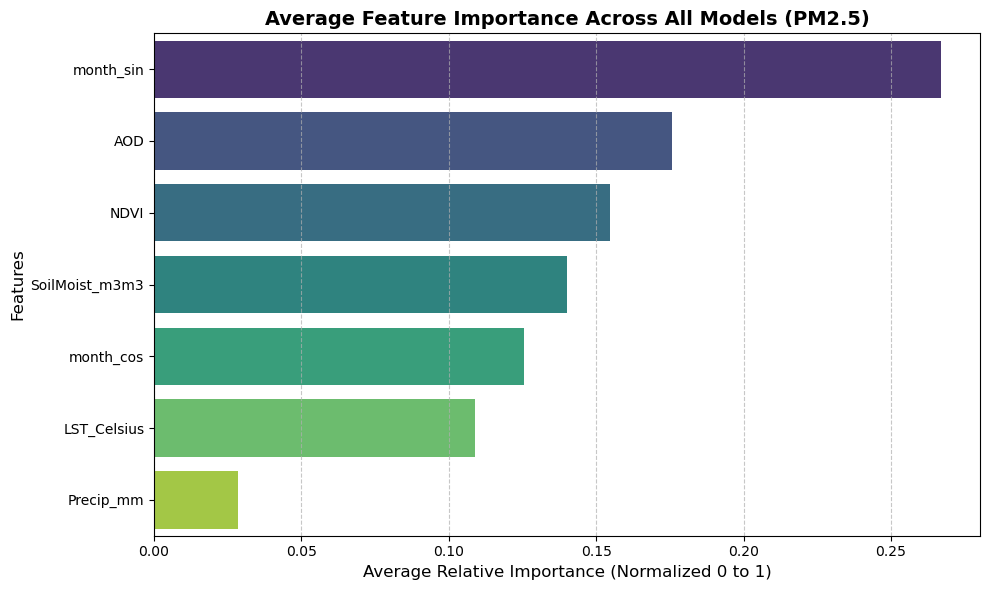

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb
import lightgbm as lgb
import optuna
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# ---------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------
df = pd.read_csv(r'C:\Users\Dell\Desktop\Air pollution research\All_station with NDVI_LST_PRECIPITATION_SOIL MOISTURE.csv')

# ---------------------------------------------------------
# 2. PREPROCESSING & FEATURE ENGINEERING
# ---------------------------------------------------------
# Convert 'date' to datetime objects
df['date'] = pd.to_datetime(df['date'])

# Extract cyclical time features (Month)
df['month'] = df['date'].dt.month
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Define features and PM2.5 target
features = ['AOD', 'NDVI', 'LST_Celsius', 'Precip_mm', 'SoilMoist_m3m3', 'month_sin', 'month_cos']
target_pm25 = 'pm25'

X = df[features]
y_pm25 = df[target_pm25]

# ---------------------------------------------------------
# 3. RANDOM TRAIN/TEST SPLIT (80% / 20%)
# ---------------------------------------------------------
X_train, X_test, y_train_25, y_test_25 = train_test_split(
    X, y_pm25, test_size=0.2, random_state=42
)

# ---------------------------------------------------------
# 4. MODEL TUNING & EVALUATION FUNCTION
# ---------------------------------------------------------
def tune_and_evaluate(model_name, X_tr, y_tr, X_te, y_te, n_trials=60):
    
    def objective(trial):
        if model_name == 'RandomForest':
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 100, 500),
                'max_depth': trial.suggest_int('max_depth', 3, 20),
                'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5)
            }
            model = RandomForestRegressor(**params, random_state=42, n_jobs=-1)
            
        elif model_name == 'GradientBoosting':
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 100, 500),
                'max_depth': trial.suggest_int('max_depth', 2, 8),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0)
            }
            model = GradientBoostingRegressor(**params, random_state=42)
            
        elif model_name == 'XGBoost':
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 100, 500),
                'max_depth': trial.suggest_int('max_depth', 2, 8),
                'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.15, log=True),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
                'min_child_weight': trial.suggest_int('min_child_weight', 1, 10)
            }
            model = xgb.XGBRegressor(**params, random_state=42, objective='reg:squarederror')
            
        elif model_name == 'LightGBM':
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 100, 500),
                'num_leaves': trial.suggest_int('num_leaves', 10, 80),
                'learning_rate': trial.suggest_float('learning_rate', 0.05, 0.15, log=True),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
                'min_child_samples': trial.suggest_int('min_child_samples', 5, 40)
            }
            model = lgb.LGBMRegressor(**params, random_state=42, verbose=-1)

        # 5-fold Random Cross Validation
        kf = KFold(n_splits=5, shuffle=True, random_state=42)
        r2_scores = []
        
        for train_index, val_index in kf.split(X_tr):
            cv_X_train, cv_X_val = X_tr.iloc[train_index], X_tr.iloc[val_index]
            cv_y_train, cv_y_val = y_tr.iloc[train_index], y_tr.iloc[val_index]
            
            model.fit(cv_X_train, cv_y_train)
            preds = model.predict(cv_X_val)
            r2_scores.append(r2_score(cv_y_val, preds))
            
        return np.mean(r2_scores)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=n_trials)
    
    best_params = study.best_params
    
    if model_name == 'RandomForest':
        final_model = RandomForestRegressor(**best_params, random_state=42, n_jobs=-1)
    elif model_name == 'GradientBoosting':
        final_model = GradientBoostingRegressor(**best_params, random_state=42)
    elif model_name == 'XGBoost':
        final_model = xgb.XGBRegressor(**best_params, random_state=42, objective='reg:squarederror')
    elif model_name == 'LightGBM':
        final_model = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1)
        
    final_model.fit(X_tr, y_tr)
    test_preds = final_model.predict(X_te)
    
    r2 = r2_score(y_te, test_preds)
    rmse = np.sqrt(mean_squared_error(y_te, test_preds))
    mae = mean_absolute_error(y_te, test_preds)
    metrics_dict = {'R2': round(r2, 3), 'RMSE': round(rmse, 2), 'MAE': round(mae, 2)}
    
    return final_model, metrics_dict

# ---------------------------------------------------------
# 5. EXECUTION PIPELINE (PM2.5 ONLY)
# ---------------------------------------------------------
models_to_run = ['RandomForest', 'GradientBoosting', 'XGBoost', 'LightGBM']

print("\n========== TRAINING FOR PM2.5 ==========")
results_pm25 = {}
trained_models_pm25 = {}

for m in models_to_run:
    print(f"Currently tuning: {m}...")
    model, metrics = tune_and_evaluate(m, X_train, y_train_25, X_test, y_test_25, n_trials=60)
    results_pm25[m] = metrics
    trained_models_pm25[m] = model

df_res_25 = pd.DataFrame(results_pm25).T.sort_values(by='R2', ascending=False)
print("\n--- PM2.5 MODEL COMPARISON ---")
print(df_res_25)

# ---------------------------------------------------------
# 6. AVERAGE FEATURE IMPORTANCE PLOT (PM2.5 ONLY)
# ---------------------------------------------------------
def plot_average_feature_importance(trained_models_dict, feature_names, target_name):
    all_importances = []
    
    for model_name, model in trained_models_dict.items():
        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
            # Normalize to 0-1 scale to average LightGBM with XGBoost/RF fairly
            if importances.sum() > 0:
                importances = importances / importances.sum()
            all_importances.append(importances)
            
    if not all_importances:
        return
        
    avg_importances = np.mean(all_importances, axis=0)
    importance_df = pd.DataFrame({'Feature': feature_names, 'Average Importance': avg_importances})
    importance_df = importance_df.sort_values(by='Average Importance', ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Average Importance', y='Feature', data=importance_df, palette='viridis')
    plt.title(f'Average Feature Importance Across All Models ({target_name})', fontsize=14, fontweight='bold')
    plt.xlabel('Average Relative Importance (Normalized 0 to 1)', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

print("\n========================================")
print(" PLOTTING AVERAGE FEATURE IMPORTANCE (PM2.5)")
print("========================================")
plot_average_feature_importance(trained_models_pm25, features, "PM2.5")


 PLOTTING AVERAGE FEATURE IMPORTANCE (PM2.5)
Chart successfully saved to: C:\Users\Dell\Downloads\PM25_Feature_Importance.png


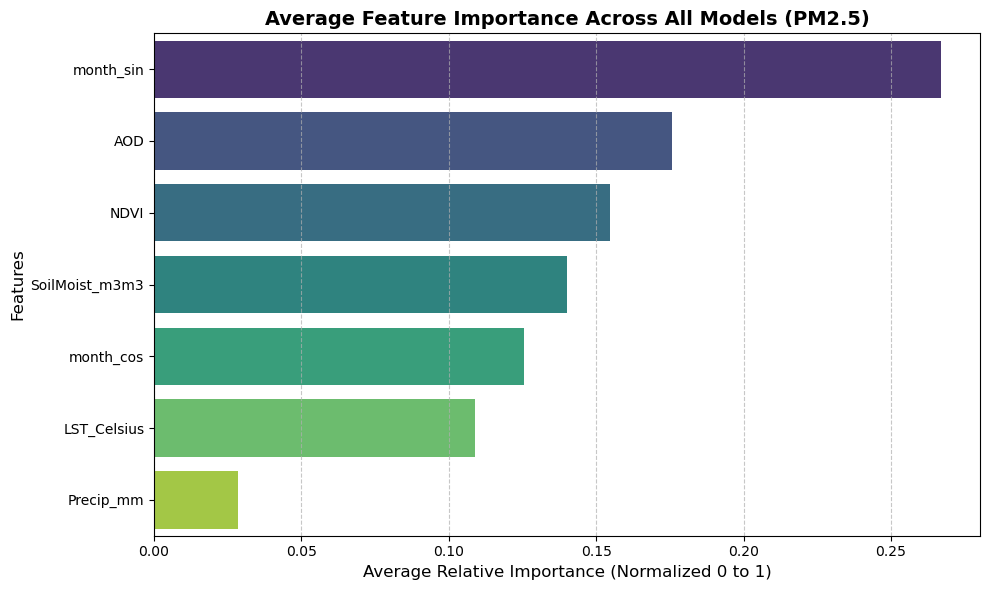

In [2]:
# ---------------------------------------------------------
# 6. AVERAGE FEATURE IMPORTANCE PLOT (PM2.5 ONLY)
# ---------------------------------------------------------
def plot_average_feature_importance(trained_models_dict, feature_names, target_name):
    all_importances = []
    
    for model_name, model in trained_models_dict.items():
        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
            # Normalize to 0-1 scale to average LightGBM with XGBoost/RF fairly
            if importances.sum() > 0:
                importances = importances / importances.sum()
            all_importances.append(importances)
            
    if not all_importances:
        return
        
    avg_importances = np.mean(all_importances, axis=0)
    importance_df = pd.DataFrame({'Feature': feature_names, 'Average Importance': avg_importances})
    importance_df = importance_df.sort_values(by='Average Importance', ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Average Importance', y='Feature', data=importance_df, palette='viridis')
    plt.title(f'Average Feature Importance Across All Models ({target_name})', fontsize=14, fontweight='bold')
    plt.xlabel('Average Relative Importance (Normalized 0 to 1)', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    
    # EXACT SAVE PATH TO YOUR DOWNLOADS FOLDER
    save_path = r'C:\Users\Dell\Downloads\PM25_Feature_Importance.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Chart successfully saved to: {save_path}")
    
    # plt.show() must always come AFTER plt.savefig()
    plt.show()

print("\n========================================")
print(" PLOTTING AVERAGE FEATURE IMPORTANCE (PM2.5)")
print("========================================")
plot_average_feature_importance(trained_models_pm25, features, "PM2.5")

 GENERATING SCATTER PLOTS FOR PM2.5 
Chart successfully saved to: C:\Users\Dell\Downloads\PM25_Actual_vs_Predicted_RandomForest.png


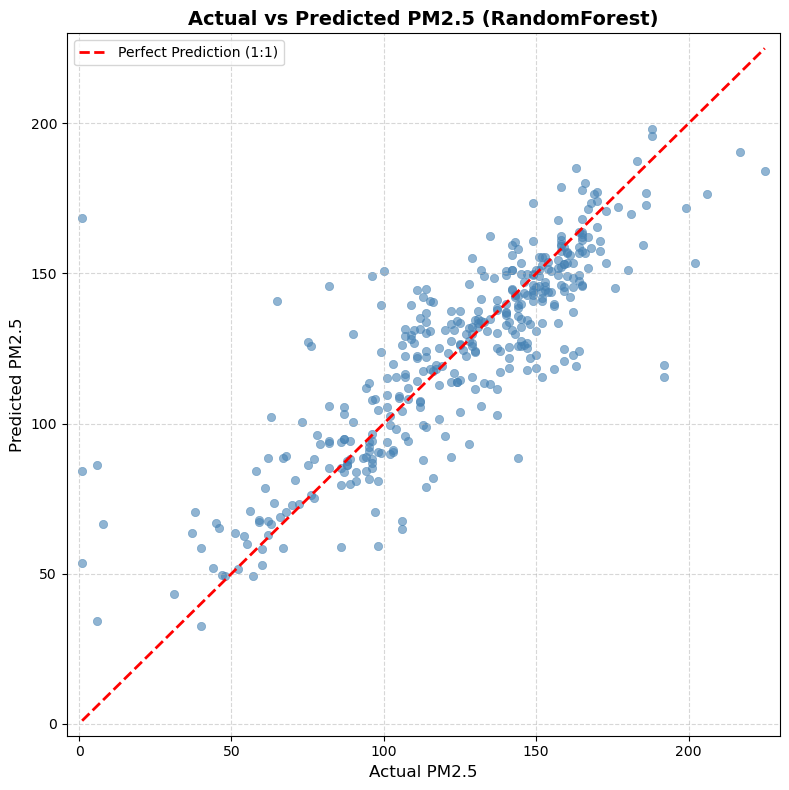

Chart successfully saved to: C:\Users\Dell\Downloads\PM25_Actual_vs_Predicted_GradientBoosting.png


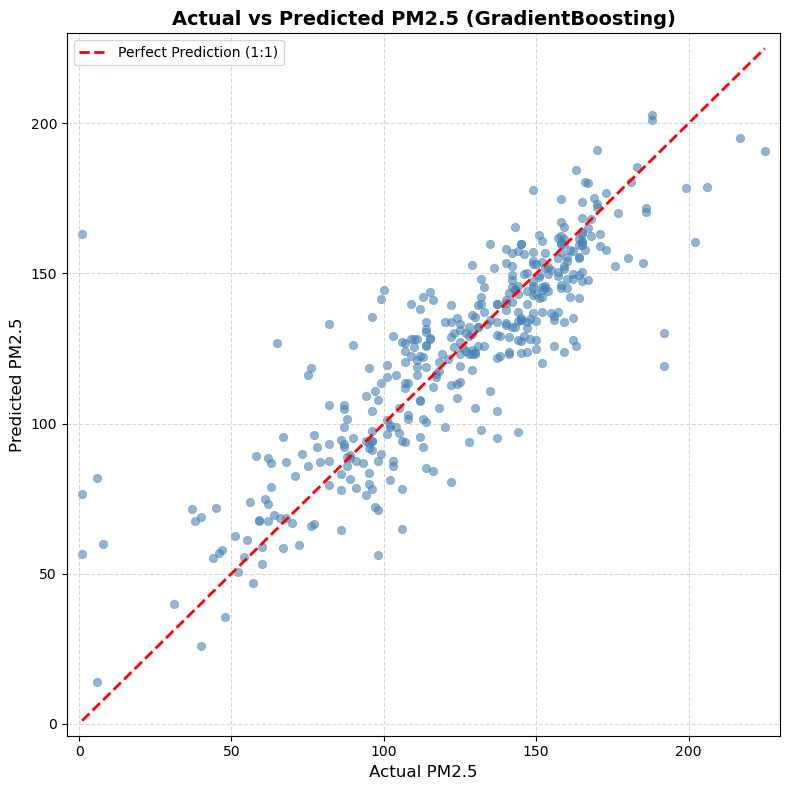

Chart successfully saved to: C:\Users\Dell\Downloads\PM25_Actual_vs_Predicted_XGBoost.png


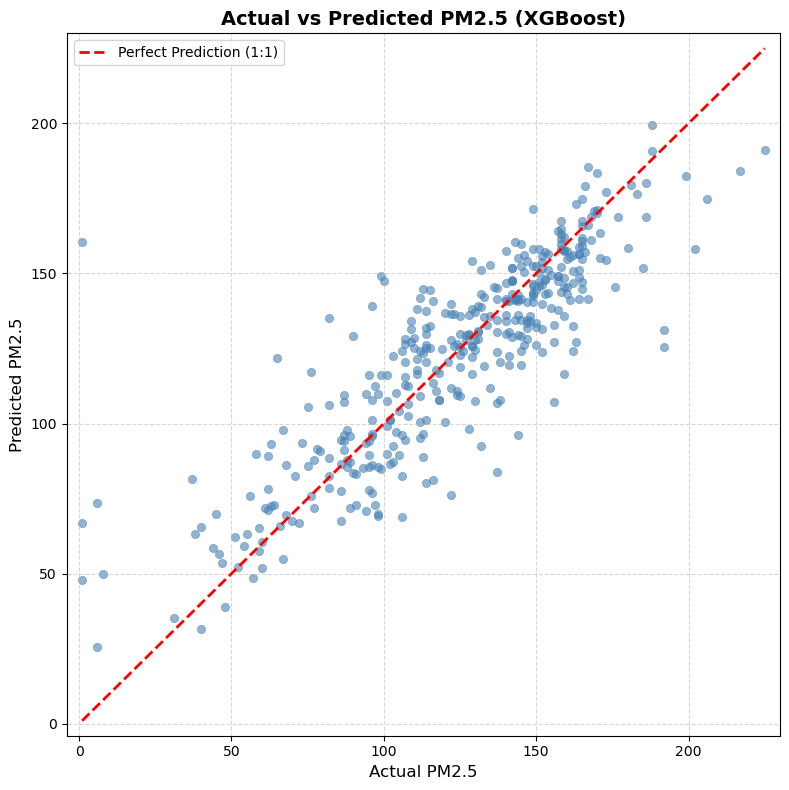

Chart successfully saved to: C:\Users\Dell\Downloads\PM25_Actual_vs_Predicted_LightGBM.png


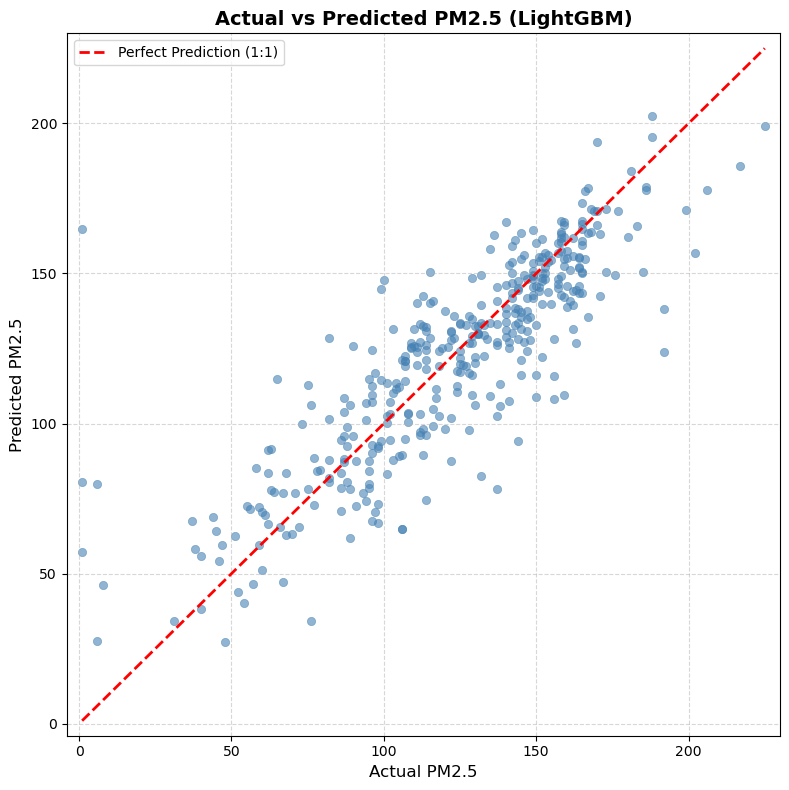

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------
# 7. ACTUAL VS PREDICTED SCATTER PLOTS (PM2.5 ONLY)
# ---------------------------------------------------------
print("========================================")
print(" GENERATING SCATTER PLOTS FOR PM2.5 ")
print("========================================")

for model_name, model in trained_models_pm25.items():
    # Make predictions on the test set
    test_preds = model.predict(X_test)
    
    # Create the scatter plot
    plt.figure(figsize=(8, 8))
    sns.scatterplot(x=y_test_25, y=test_preds, alpha=0.6, color='steelblue', edgecolor=None)
    
    # Calculate the min and max limits to draw the perfect 1:1 prediction line
    min_val = min(y_test_25.min(), test_preds.min())
    max_val = max(y_test_25.max(), test_preds.max())
    
    # Plot the 1:1 perfect prediction line (y = x)
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (1:1)')
    
    # Formatting
    plt.title(f'Actual vs Predicted PM2.5 ({model_name})', fontsize=14, fontweight='bold')
    plt.xlabel('Actual PM2.5', fontsize=12)
    plt.ylabel('Predicted PM2.5', fontsize=12)
    
    # Lock the axes limits so the chart is a perfect square
    plt.xlim([min_val - 5, max_val + 5])
    plt.ylim([min_val - 5, max_val + 5])
    
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    
    # Save the plot explicitly to your Downloads folder
    save_path = fr'C:\Users\Dell\Downloads\PM25_Actual_vs_Predicted_{model_name}.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    print(f"Chart successfully saved to: {save_path}")
    
    # Display the plot in the notebook (must come AFTER plt.savefig)
    plt.show()

 GENERATING SKEWNESS HISTOGRAMS 
Chart successfully saved to: C:\Users\Dell\Downloads\Feature_Distributions_Skewness.png


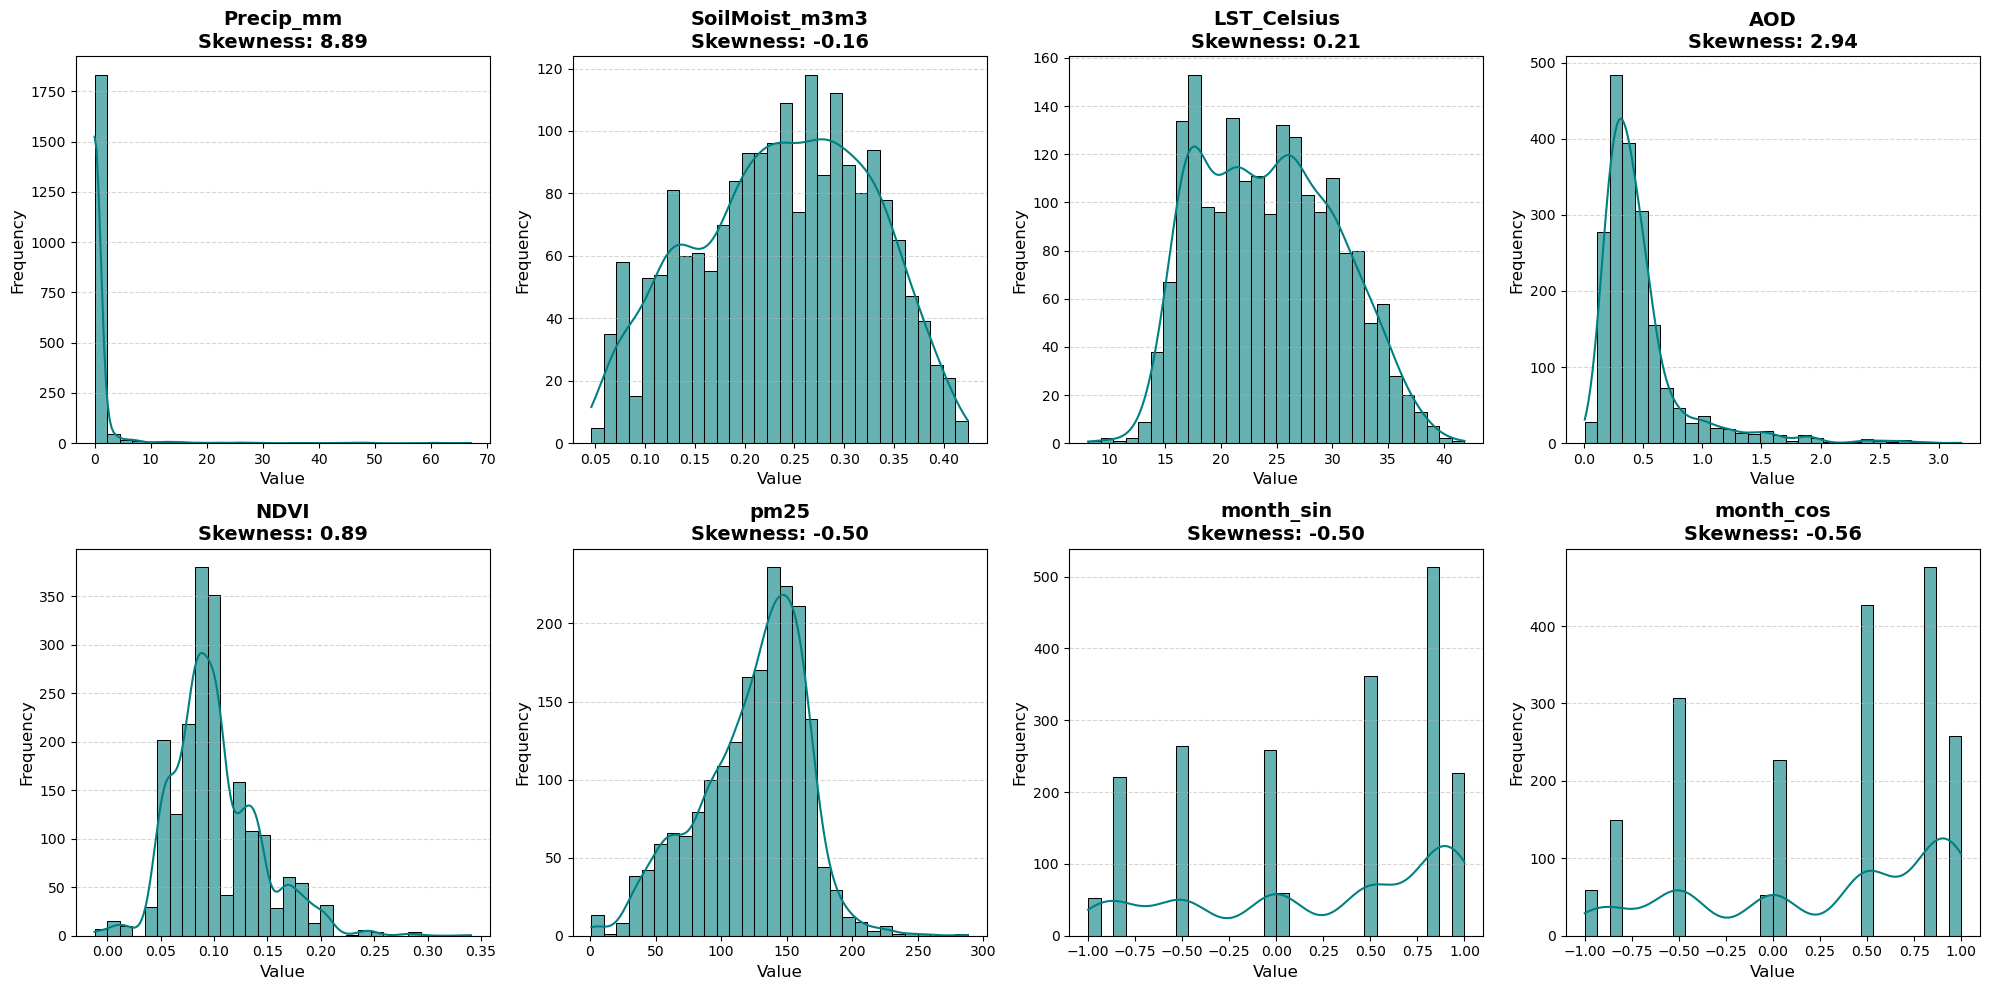

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the columns you want to visualize
cols_to_plot = [
    'Precip_mm', 'SoilMoist_m3m3', 'LST_Celsius', 
    'AOD', 'NDVI', 'pm25', 'month_sin', 'month_cos'
]

print("========================================")
print(" GENERATING SKEWNESS HISTOGRAMS ")
print("========================================")

# Set up a grid figure (2 rows, 4 columns to fit all 8 charts neatly)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axes = axes.flatten() # Flatten to loop through easily

# Loop through each column and generate its histogram
for i, col in enumerate(cols_to_plot):
    # Calculate the mathematical skewness
    skew_val = df[col].skew()
    
    # Plot histogram with the smooth density curve (kde=True)
    sns.histplot(df[col], kde=True, bins=30, ax=axes[i], color='teal', edgecolor='black', alpha=0.6)
    
    # Format the subplot title to show the variable name and its skewness score
    axes[i].set_title(f'{col}\nSkewness: {skew_val:.2f}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Value', fontsize=12)
    axes[i].set_ylabel('Frequency', fontsize=12)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

# Adjust layout to prevent overlapping labels
plt.tight_layout()

# Save the grid plot to your Downloads folder
save_path = r'C:\Users\Dell\Downloads\Feature_Distributions_Skewness.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Chart successfully saved to: {save_path}")

# Display the plot in the notebook
plt.show()

 GENERATING SKEWNESS HISTOGRAMS (3-3-2 LAYOUT) 
Chart successfully saved to: C:\Users\Dell\Downloads\Feature_Distributions_Skewness.png


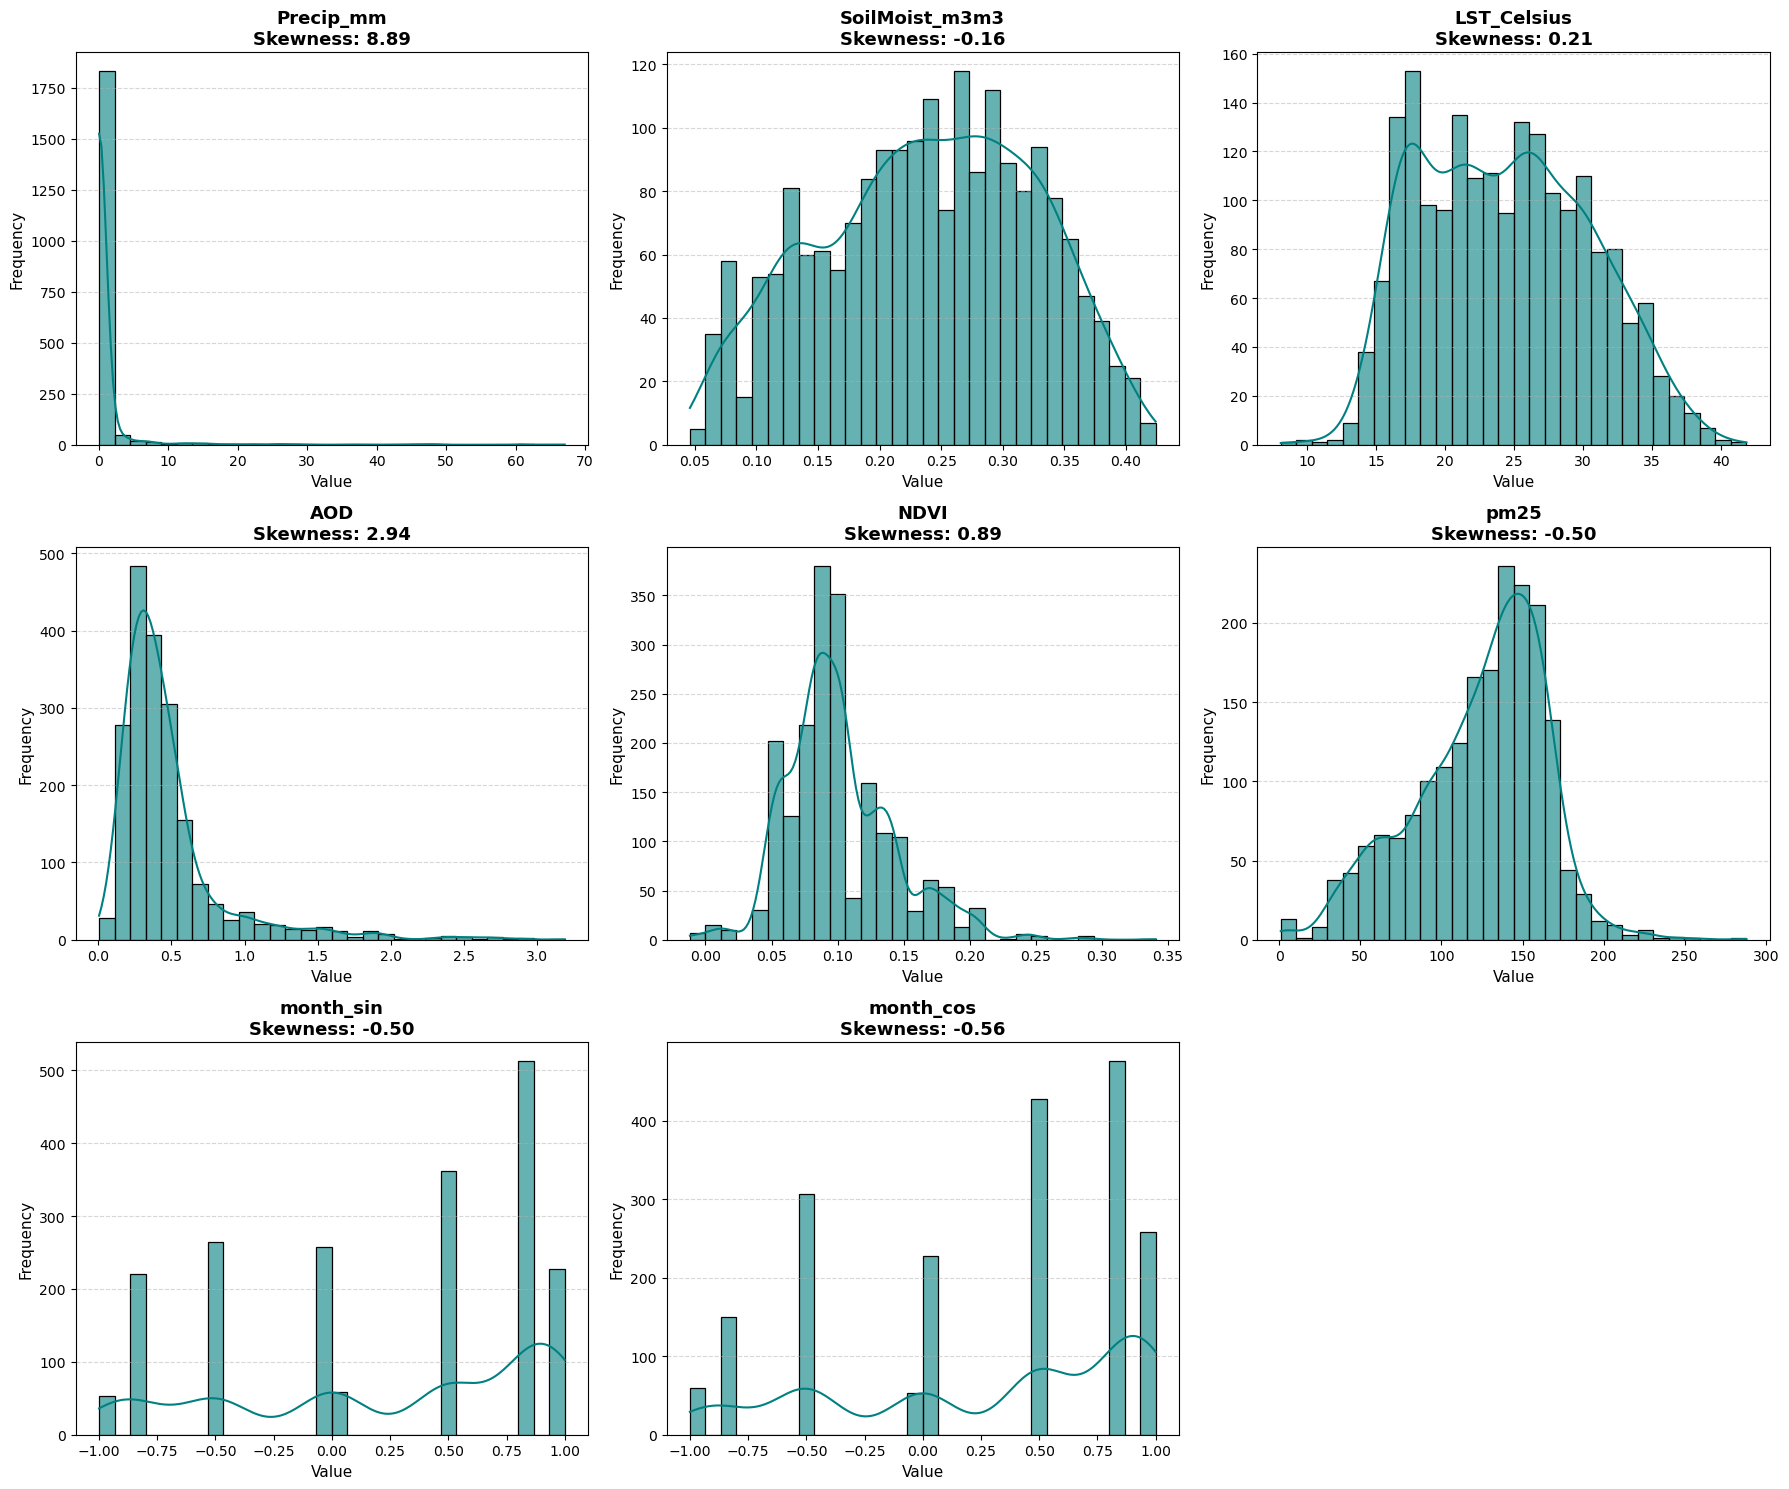

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the 8 columns to visualize
cols_to_plot = [
    'Precip_mm', 'SoilMoist_m3m3', 'LST_Celsius', 
    'AOD', 'NDVI', 'pm25', 'month_sin', 'month_cos'
]

print("========================================")
print(" GENERATING SKEWNESS HISTOGRAMS (3-3-2 LAYOUT) ")
print("========================================")

# Set up a 3x3 grid (9 subplots total: Row 1 = 3, Row 2 = 3, Row 3 = 2 + 1 empty)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 15))
axes = axes.flatten()

# Plot the 8 features
for i, col in enumerate(cols_to_plot):
    skew_val = df[col].skew()
    
    sns.histplot(df[col], kde=True, bins=30, ax=axes[i], color='teal', edgecolor='black', alpha=0.6)
    axes[i].set_title(f'{col}\nSkewness: {skew_val:.2f}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Value', fontsize=11)
    axes[i].set_ylabel('Frequency', fontsize=11)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

# Hide the 9th empty plot slot so the last row only contains 2 charts
axes[-1].set_visible(False)

# Adjust layout to prevent overlapping labels
plt.tight_layout()

# Save the grid plot to your Downloads folder
save_path = r'C:\Users\Dell\Downloads\Feature_Distributions_Skewness.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Chart successfully saved to: {save_path}")

# Display the plot
plt.show()